In [1]:
from google.colab import drive, userdata

try:
    repo_url = f"https://{userdata.get('GH_TOKEN')}@github.com/duyenphung206-sudo/vit-oxford-pets.git"
except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
    repo_url = "https://github.com/duyenphung206-sudo/vit-oxford-pets.git"
!git clone -q {repo_url} /content/vit-oxford-pets
%cd /content/vit-oxford-pets
!pip install -q -r requirements.txt
drive.mount("/content/drive")

/content/vit-oxford-pets
Mounted at /content/drive


In [2]:
from torchvision.datasets import OxfordIIITPet

# tai dataset vao o tam cua Colab (khong dua len GitHub)
for split in ("trainval", "test"):
    OxfordIIITPet("/content/data", split=split, download=True)

100%|██████████| 792M/792M [00:29<00:00, 26.4MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 9.23MB/s]


In [3]:
!python -m src.train --config configs/e4_vit_full_ft.yaml --fake-data --epochs 1 --output-dir /content/smoke --checkpoint-dir /content/smoke_ckpt

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth
100% 330M/330M [00:02<00:00, 145MB/s]
e4_vit_full_ft | seed 42 | cuda | trainable 85,827,109 / 85,827,109
epoch   1/1 | train 3.6118 / 0.0234 | val 3.6106 / 0.0391 | 7s
best epoch 1 | val loss 3.6106 | val acc 0.0391


In [4]:
for seed in (42, 43, 44):
    !python -m src.train --config configs/e4_vit_full_ft.yaml --seed {seed} --checkpoint-dir /content/drive/MyDrive/vit-oxford-pets/checkpoints/e4_vit_full_ft/seed{seed}

e4_vit_full_ft | seed 42 | cuda | trainable 85,827,109 / 85,827,109
epoch   1/10 | train 3.3798 / 0.8128 | val 2.8098 / 0.9076 | 47s
epoch   2/10 | train 2.0378 / 0.8995 | val 1.3147 / 0.8981 | 48s
epoch   3/10 | train 0.9742 / 0.9243 | val 0.7000 / 0.9171 | 55s
epoch   4/10 | train 0.5894 / 0.9375 | val 0.4909 / 0.9334 | 54s
epoch   5/10 | train 0.4372 / 0.9484 | val 0.4024 / 0.9457 | 54s
epoch   6/10 | train 0.3610 / 0.9548 | val 0.3544 / 0.9511 | 55s
epoch   7/10 | train 0.3196 / 0.9596 | val 0.3315 / 0.9538 | 56s
epoch   8/10 | train 0.2920 / 0.9660 | val 0.3172 / 0.9524 | 56s
epoch   9/10 | train 0.2817 / 0.9654 | val 0.3119 / 0.9538 | 56s
epoch  10/10 | train 0.2791 / 0.9681 | val 0.3112 / 0.9552 | 58s
best epoch 10 | val loss 0.3112 | val acc 0.9552
e4_vit_full_ft | seed 43 | cuda | trainable 85,827,109 / 85,827,109
epoch   1/10 | train 3.3823 / 0.7921 | val 2.8175 / 0.8954 | 60s
epoch   2/10 | train 2.0489 / 0.8967 | val 1.3249 / 0.9076 | 50s
epoch   3/10 | train 0.9824 / 0.912

In [5]:
from src.summarize import plot_curves, summarize_runs

summary = summarize_runs("results/e4_vit_full_ft")
for key in ("best_val_acc", "best_val_loss", "best_epoch", "mean_epoch_time_s"):
    print(f"{key:<18} {summary[key]['mean']:.4f} +/- {summary[key]['std']:.4f}")
plot_curves("results/e4_vit_full_ft", "figures/e4_curves.png")

best_val_acc       0.9547 +/- 0.0008
best_val_loss      0.3097 +/- 0.0019
best_epoch         10.0000 +/- 0.0000
mean_epoch_time_s  55.2000 +/- 1.1432


PosixPath('figures/e4_curves.png')

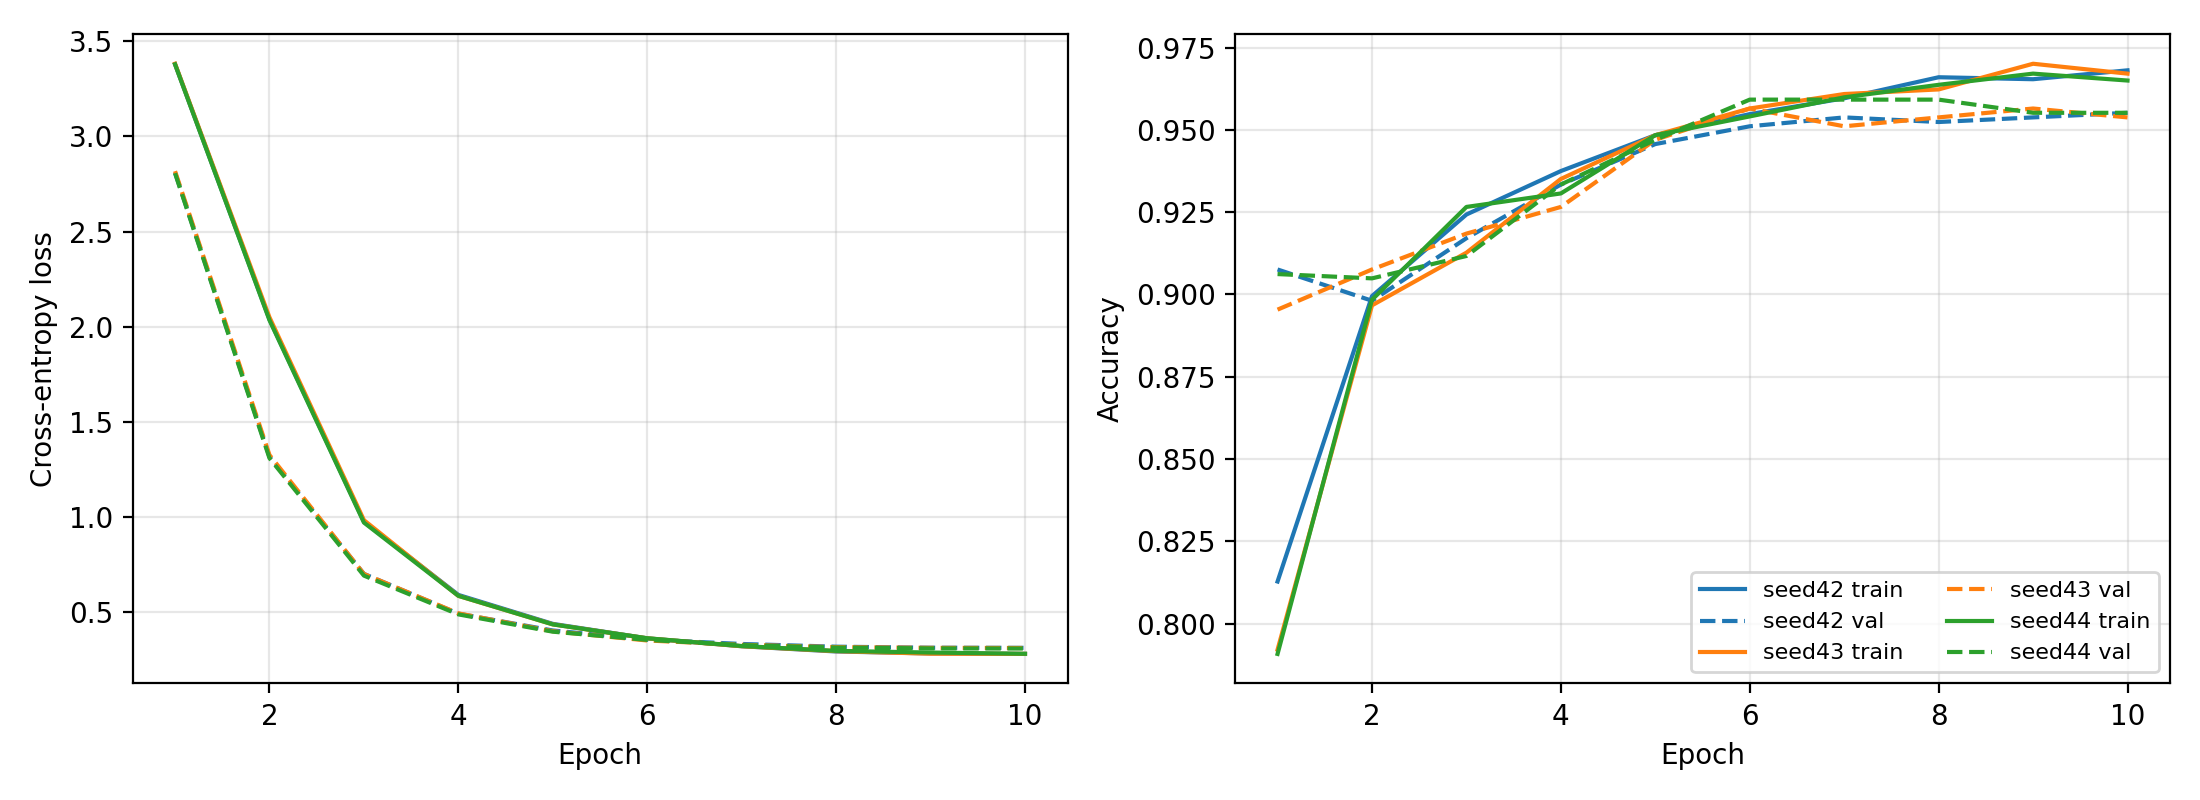

In [6]:
from IPython.display import Image

Image("figures/e4_curves.png")

In [7]:
from google.colab import files

!zip -q -r /content/e4_results.zip results/e4_vit_full_ft figures/e4_curves.png
files.download("/content/e4_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>